# Research Methods for AI & Data Science: Reproducibility and Research Code

> **Who is this for?** MS/MPhil students and engineers who run ML experiments and want someone else (a reviewer, a supervisor, a colleague, or *you in six months*) to get the same results. No prior research experience is needed.
>
> **What you will learn**
> - The reproducibility crisis in ML, and the difference between **repeatable**, **reproducible** and **replicable**
> - Seeds and determinism in Python, NumPy and PyTorch, demonstrated, and what is **not** guaranteed (floating point, GPUs, versions)
> - Environment pinning: `requirements.txt`, lock files, `pip freeze`, conda, Docker, and recording versions from code
> - A research project layout, YAML configs with `argparse` (Hydra-style `key=value` overrides) and command-line experiment scripts
> - Experiment tracking: a minimal JSON/CSV tracker built from scratch, then MLflow with a temporary local store
> - Data versioning with checksums (`hashlib`), datasheets for datasets and model cards filled in by code
> - Sharing: code release, licences, DOIs, the Hugging Face Hub, and a filled reproducibility checklist
> - **Reproducing a "paper result"** with a tolerance, and documenting discrepancies
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb), [your first ML model](../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb), [model evaluation](../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb), [pipelines and leakage](../03_Machine_Learning/01_supervised/09_pipeline_and_leakage.ipynb), and the previous notebooks of this module, especially [02 Experiment design](02_experiment_design_for_ml.ipynb) and [03 Statistical significance](03_statistical_significance_and_reporting.ipynb). Helpful: [MLflow](../15_MLOps/01_experiment_tracking/01_mlflow.ipynb), [DVC](../15_MLOps/02_data_versioning/01_dvc.ipynb).
>
> **Time needed:** about 2–3 hours.
>
> **Runs on:** CPU, no API key, no internet, no Docker. Every file is written to a temporary folder that is deleted at the end.
>
> **Optional track:** this notebook is part of the university-level fundamentals track (module 24, *Research Methods for AI & Data Science*); recommended for BS/MS AI students, thesis writers and interview prep for research roles.

## Explained simply

Research is only useful if other people can check it. **Reproducibility** means that someone else can take your code and data, run them, and get the same numbers you reported. That sounds easy, but computers hide many small "random" choices, programs change between versions, and data files get edited, so the same experiment can quietly give a different answer next month. This notebook shows how to write down *everything* that affects a result, so nobody has to guess.

- **Everyday example 1, a recipe:** "add some flour, bake until done" only works in the author's kitchen. "250 g flour, 180 °C, 35 minutes, 20 cm tin" works in anyone's kitchen.
- **Everyday example 2, a school science experiment:** your teacher asks for the method, the equipment and the measurements, so a classmate can repeat it and check your conclusion.

**Tiny concrete example:** you shuffle a deck of 52 cards and deal the top 5. If you write down "shuffle number 42" (a *seed*) and your friend's computer also uses shuffle number 42, you both get exactly the same 5 cards. If you forget to write the number, your friend gets different cards and might get a different score, even though nobody made a mistake.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Random seed | the "shuffle number" that makes random choices repeatable | splitting data into train/test, initialising a neural network |
| Environment pinning | writing down the exact versions of every tool you used | `requirements.txt`, Docker images, Colab notebooks that break after an update |
| Checksum | a fingerprint of a file that changes if even one byte changes | checking a downloaded dataset or app installer has not been altered |

### Table of contents
1. Setup
2. The reproducibility crisis and three levels of "same result"
3. Seeds and determinism (and what is not guaranteed)
4. Environment pinning and recording versions
5. Project structure, configs and command-line experiment scripts
6. Experiment tracking: a minimal tracker, then MLflow
7. Data versioning with checksums
8. Datasheets for datasets and model cards
9. Sharing artefacts: code, licences, DOIs, the Hub, the checklist
10. Case study: reproducing a "paper result"
11. How this connects to modern AI
12. Recap, practice problems, further reading

**How this notebook relates to `15_MLOps`.** The MLOps module teaches the *tools* in depth for production ([MLflow](../15_MLOps/01_experiment_tracking/01_mlflow.ipynb), [Weights & Biases](../15_MLOps/01_experiment_tracking/02_wandb.ipynb), [advanced tracking](../15_MLOps/10_advanced_experiment_tracking.ipynb), [DVC](../15_MLOps/02_data_versioning/01_dvc.ipynb)). Here we focus on the *research* question, **"can someone else get my numbers?"**, and build the minimal version of each idea ourselves so you understand what the tools do.

---
## 1. Setup

> 💡 **In plain English:** we load the tools and create a temporary folder so nothing is written into the repository.

In [1]:
import csv                                   # the minimal tracker writes a CSV file
import hashlib                               # SHA-256 checksums
import importlib.metadata as md              # installed package versions
import json
import logging
import math
import os
import platform                              # OS / CPU / Python information
import random                                # Python's own random number generator
import shutil
import subprocess                            # run scripts as separate processes (like a terminal)
import sys
import tempfile
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")     # no usage telemetry from a tutorial
os.environ.setdefault("DO_NOT_TRACK", "true")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import yaml                                  # PyYAML: read/write YAML config files
from IPython.display import Markdown, display
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

WORK = Path(tempfile.mkdtemp(prefix="repro_"))       # everything we write goes here
pd.set_option("display.width", 140)
print("Python", platform.python_version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

Python 3.12.3 | numpy 2.4.6 | scikit-learn 1.9.0


---
## 2. The reproducibility crisis and three levels of "same result"

> 💡 **In plain English:** many published ML results cannot be re-created, and there are three different levels of "getting the same result".

**Analogy.** A cake recipe that says "add some flour and bake until done" might work in the author's kitchen, with the author's oven. A *reproducible* recipe gives exact amounts, oven temperature, tin size and time, so a stranger gets the same cake.

Many published ML results are hard to reproduce. Some well-documented examples:
- **Henderson et al. (AAAI 2018)**, *Deep Reinforcement Learning that Matters*: the same algorithm with different random seeds (and different but "equivalent" implementations) gave significantly different learning curves; reported improvements were often within seed noise.
- **Gundersen & Kjensmo (AAAI 2018)** surveyed 400 AI papers from top conferences and found that most did not share their code, and many did not document data or experiment details well enough to reproduce them.
- **Bouthillier et al. (MLSys 2021)**, *Accounting for Variance in Machine Learning Benchmarks*: data splits, initialisation and hyper-parameter search all add variance, and single-run comparisons often mislead.
- **Kapoor & Narayanan (Patterns, 2023)**, *Leakage and the Reproducibility Crisis in ML-based Science*: data leakage affected hundreds of published papers across many scientific fields.
- In response, NeurIPS introduced a **reproducibility checklist** and code-submission policy (Pineau et al., *JMLR* 2021, report on the NeurIPS 2019 reproducibility programme), and the community runs a yearly **ML Reproducibility Challenge**.

### Three levels

Different fields use these words differently (ACM's artifact badges even swapped two of them in 2020 to match the US National Academies' 2019 report). The usage below follows the National Academies and current ACM terminology:

| Level | Who | Same code? | Same data? | Question answered | ML example |
|---|---|---|---|---|---|
| **Repeatable** | same team, same setup | yes | yes | "Do I get my own number again?" | re-running your script tomorrow gives 0.978 again |
| **Reproducible** | a different team | yes (the authors' code) | yes | "Is the reported number what this code produces?" | a reviewer runs your repo and gets 0.978 ± noise |
| **Replicable** | a different team | no (new implementation) | new data / new setup | "Does the *conclusion* hold?" | another lab re-implements the method on a new dataset and still finds it beats the baseline |

Each level is a stronger test. Reproducibility checks that you did what you said; replicability checks that what you found is true more generally.

### Why results fail to reproduce

| Source | Example | Fix (section) |
|---|---|---|
| Randomness | unseeded weight initialisation, data shuffling, splits | seeds, many runs (§3) |
| Software versions | default hyper-parameters changed between library versions | pin and record versions (§4) |
| Hardware / numerics | GPU kernels sum in a different order | determinism flags, report variance (§3) |
| Undocumented choices | preprocessing, early stopping, the "best" checkpoint | configs, scripts (§5) |
| Lost results | "which run was that?" | experiment tracking (§6) |
| Data changes | a dataset re-downloaded with corrections | checksums, versioning (§7) |
| Leakage and evaluation bugs | scaling fitted on all data, test set used for tuning | pipelines, nested CV (§10, notebook 06) |
| Selective reporting | best of 20 seeds reported as "the" result | report all runs, pre-register (notebook 06) |

> 🎓 **Exam / interview tip:** "What is the difference between reproducibility and replicability?" Answer with the table: same code + same data vs new implementation/data, and say that terminology differs between fields, so define it in your paper.

---
## 3. Seeds and determinism

> 💡 **In plain English:** random numbers in computers are repeatable if you fix the starting number (the seed), but some tiny differences still remain.

A computer's "random" numbers come from a **pseudo-random number generator (PRNG)**: a deterministic algorithm that produces a sequence that *looks* random, starting from an initial value called the **seed**. Same seed → same sequence. Python's `random` uses the Mersenne Twister; NumPy's modern `Generator` uses PCG64 by default; PyTorch has its own generators for CPU and each GPU.

**Important:** each library has its **own** generator. Seeding one does not seed the others.

In [2]:
import torch

torch.set_num_threads(1)                      # small, fast and less variable on a shared CPU


def set_seed(seed: int) -> None:
    """Seed every random number generator a typical ML script uses."""
    random.seed(seed)                         # Python's built-in generator
    np.random.seed(seed)                      # NumPy's legacy global generator (used by older code)
    torch.manual_seed(seed)                   # PyTorch CPU generator (and all CUDA devices, if present)


def sample_all() -> tuple:
    return (random.random(), float(np.random.rand()), float(torch.rand(1)))


set_seed(42); a = sample_all()
set_seed(42); b = sample_all()
set_seed(7);  c = sample_all()
print("seed 42, run 1:", np.round(a, 6))
print("seed 42, run 2:", np.round(b, 6))
print("seed 7        :", np.round(c, 6))
assert a == b and a != c

# Seeding only NumPy does NOT fix Python's or PyTorch's numbers:
np.random.seed(42); x1 = (random.random(), float(torch.rand(1)))
np.random.seed(42); x2 = (random.random(), float(torch.rand(1)))
print("only numpy seeded -> python/torch values equal?", x1 == x2)

seed 42, run 1: [0.639427 0.37454  0.882269]
seed 42, run 2: [0.639427 0.37454  0.882269]
seed 7        : [0.323833 0.076308 0.534923]
only numpy seeded -> python/torch values equal? False


**What just happened?** With all three generators seeded, two runs give identical numbers and a different seed gives different numbers. Seeding NumPy alone left Python's and PyTorch's numbers different between the two runs.

### 3.1 Prefer local generators

Global seeds are fragile: any library call that draws a random number changes everything after it. Modern NumPy recommends a **local generator** object passed around explicitly, and `SeedSequence.spawn` to give parallel workers independent streams.

In [3]:
rng = np.random.default_rng(2026)                     # a local generator: nothing global is touched
print("local generator:", rng.integers(0, 100, 5))

# Independent streams for 3 parallel workers, all derived from ONE recorded seed
children = np.random.SeedSequence(2026).spawn(3)
streams = [np.random.default_rng(s) for s in children]
print("worker streams :", [g.integers(0, 100, 3).tolist() for g in streams])

# scikit-learn: pass an int as random_state; None means "different every time"
X_bc, y_bc = load_breast_cancer(return_X_y=True)
first_test_labels = [train_test_split(X_bc, y_bc, test_size=0.25, random_state=rs)[3][:10] for rs in (0, 0, 1)]
for rs, labels in zip((0, 0, 1), first_test_labels):
    print(f"random_state={rs}: first test labels {labels.tolist()}")
assert np.array_equal(first_test_labels[0], first_test_labels[1])          # same seed -> same split

local generator: [85 17  2 63 36]
worker streams : [[62, 38, 17], [74, 67, 64], [8, 55, 89]]
random_state=0: first test labels [0, 1, 1, 1, 1, 1, 1, 1, 1, 1]
random_state=0: first test labels [0, 1, 1, 1, 1, 1, 1, 1, 1, 1]
random_state=1: first test labels [1, 0, 1, 0, 0, 0, 0, 0, 1, 1]


### 3.2 A hidden source: hash randomisation

Python randomises the hash of strings **per process** (a security feature). That changes the iteration order of a `set` of strings between runs, so code like `for name in set(columns)` can process items in a different order each time. The `PYTHONHASHSEED` environment variable fixes it. We start fresh Python processes to see this:

In [4]:
snippet = "print(hash('reproducible') % 1000, list({'alpha', 'beta', 'gamma', 'delta'}))"
env_random = {k: v for k, v in os.environ.items() if k != "PYTHONHASHSEED"}          # default: randomised
env_fixed = {**env_random, "PYTHONHASHSEED": "0"}


def run_python(env):
    return subprocess.run([sys.executable, "-c", snippet], env=env, capture_output=True, text=True).stdout.strip()


print("PYTHONHASHSEED unset:", [run_python(env_random) for _ in range(3)])
print("PYTHONHASHSEED=0    :", [run_python(env_fixed) for _ in range(3)])

PYTHONHASHSEED unset: ["271 ['beta', 'alpha', 'delta', 'gamma']", "900 ['delta', 'beta', 'alpha', 'gamma']", "56 ['beta', 'gamma', 'alpha', 'delta']"]


PYTHONHASHSEED=0    : ["588 ['alpha', 'delta', 'beta', 'gamma']", "588 ['alpha', 'delta', 'beta', 'gamma']", "588 ['alpha', 'delta', 'beta', 'gamma']"]


**What just happened?** Without `PYTHONHASHSEED` the hash (and, often, the set order) changes between processes; with it fixed, all three processes agree. It must be set **before** Python starts (in the shell or the job script), not inside the program. The real fix is to not depend on set order: use `sorted(...)`.

### 3.3 Deterministic PyTorch training

We train a tiny neural network twice with the same seed and check that the final weights are **bit-for-bit identical**. The standard recipe also sets PyTorch's determinism switches, which matter on GPUs:

In [5]:
def make_deterministic(seed: int) -> None:
    set_seed(seed)
    torch.use_deterministic_algorithms(True)      # error out if an op has no deterministic implementation
    torch.backends.cudnn.deterministic = True     # GPU convolutions: deterministic algorithms only
    torch.backends.cudnn.benchmark = False        # do not auto-pick the fastest (possibly different) algorithm
    # For CUDA >= 10.2 some cuBLAS ops also need this env var, set before CUDA starts:
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")


def train_tiny(seed: int, steps: int = 200):
    make_deterministic(seed)
    X = torch.randn(256, 10)                                       # synthetic data (seeded)
    y = (X[:, 0] + 0.5 * X[:, 1] > 0).float().unsqueeze(1)
    model = torch.nn.Sequential(torch.nn.Linear(10, 16), torch.nn.ReLU(), torch.nn.Linear(16, 1))
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    g = torch.Generator().manual_seed(seed)                        # its own generator for mini-batch order
    for _ in range(steps):
        idx = torch.randperm(256, generator=g)[:32]                # a random mini-batch
        loss = torch.nn.functional.binary_cross_entropy_with_logits(model(X[idx]), y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    return model, float(loss)


m1, loss1 = train_tiny(0)
m2, loss2 = train_tiny(0)
m3, loss3 = train_tiny(1)
same = all(torch.equal(p, q) for p, q in zip(m1.parameters(), m2.parameters()))
print(f"seed 0: final loss {loss1:.6f} | seed 0 again: {loss2:.6f} | seed 1: {loss3:.6f}")
print("weights bit-identical for the same seed:", same)
assert same and loss1 == loss2 and loss1 != loss3
torch.use_deterministic_algorithms(False)                          # back to the default for the rest

seed 0: final loss 0.096043 | seed 0 again: 0.096043 | seed 1: 0.165095
weights bit-identical for the same seed: True


For a PyTorch `DataLoader` with several workers, also pass a seeded `generator=` and a `worker_init_fn` that seeds NumPy/`random` inside each worker (the PyTorch "Reproducibility" documentation page shows the pattern).

### 3.4 What is *not* guaranteed

Even with every seed fixed, results can differ:

1. **Floating-point addition is not associative**: $(a+b)+c$ can differ from $a+(b+c)$ in the last bits. On a GPU, thousands of threads add numbers in an order that depends on scheduling (e.g. atomic additions), so sums can differ run to run. See the demo below.
2. **Different hardware / libraries**: CPU vs GPU, different GPU models, MKL vs OpenBLAS, different numbers of threads, and TF32 / mixed precision all change the low-order bits.
3. **Different library versions**: the PyTorch documentation states that completely reproducible results are not guaranteed across releases, individual commits or platforms; scikit-learn has changed default hyper-parameters between versions.
4. **Small differences grow**: in long non-convex training, a difference in the 7th digit can change which local minimum you end in.

In [6]:
print("(0.1 + 0.2) + 0.3 =", repr((0.1 + 0.2) + 0.3))
print("0.1 + (0.2 + 0.3) =", repr(0.1 + (0.2 + 0.3)))

values = np.random.default_rng(0).normal(size=20_000).astype(np.float32)    # the SAME 20,000 numbers in every order
orders = {"original order": values, "sorted": np.sort(values), "reversed": values[::-1],
          "shuffled": np.random.default_rng(1).permutation(values)}


def sequential_sum(v):
    """Add one number at a time, like a single thread would (NumPy's own sum uses pairwise blocks)."""
    total = np.float32(0.0)
    for x in v:
        total = np.float32(total + x)
    return total


sums = {name: float(sequential_sum(v)) for name, v in orders.items()}
for name, s in sums.items():
    print(f"float32 sum, {name:14s}: {s!r}")
print("distinct results:", len(set(sums.values())), "| exact sum (math.fsum in float64):", round(math.fsum(values.astype(float)), 4))

(0.1 + 0.2) + 0.3 = 0.6000000000000001
0.1 + (0.2 + 0.3) = 0.6
float32 sum, original order: 93.6290054321289
float32 sum, sorted        : 93.63789367675781
float32 sum, reversed      : 93.62876892089844
float32 sum, shuffled      : 93.62906646728516
distinct results: 4 | exact sum (math.fsum in float64): 93.6288


**What just happened?** The same numbers added in different orders give **different float32 totals**. A GPU reduction that changes the order between runs therefore changes results slightly, even with perfect seeding. This is why papers should report **variation over several seeds** rather than promise bit-identical numbers on every machine.

### 3.5 A seed is not a hyper-parameter

The seed changes the result, so it is tempting to try many and report the best. That is **selective reporting**. Look at how much one model's test accuracy moves just because of the train/test split seed:

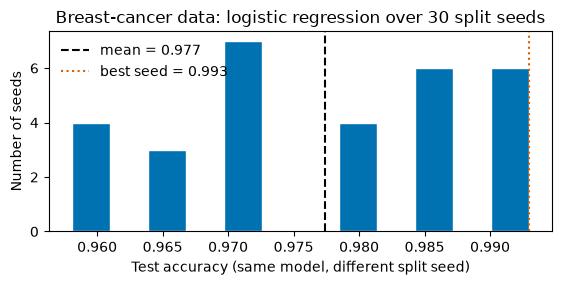

min 0.958 | mean 0.977 | max 0.993 | std 0.012


In [7]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
acc_by_seed = []
for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X_bc, y_bc, test_size=0.25, stratify=y_bc, random_state=seed)
    acc_by_seed.append(pipe.fit(Xtr, ytr).score(Xte, yte))
acc_by_seed = np.array(acc_by_seed)

fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.hist(acc_by_seed, bins=12, color="#0072B2", edgecolor="white")
ax.axvline(acc_by_seed.mean(), color="black", ls="--", label=f"mean = {acc_by_seed.mean():.3f}")
ax.axvline(acc_by_seed.max(), color="#D55E00", ls=":", label=f"best seed = {acc_by_seed.max():.3f}")
ax.set_xlabel("Test accuracy (same model, different split seed)"); ax.set_ylabel("Number of seeds")
ax.set_title("Breast-cancer data: logistic regression over 30 split seeds"); ax.legend(frameon=False)
plt.show()
print(f"min {acc_by_seed.min():.3f} | mean {acc_by_seed.mean():.3f} | max {acc_by_seed.max():.3f} | std {acc_by_seed.std(ddof=1):.3f}")

**What just happened?** Nothing about the model changed, yet the test accuracy spans several percentage points across the 30 split seeds. Reporting only the best seed would overstate the model by roughly the gap between the dotted and dashed lines. **Report the mean and spread over all seeds (and fix the list of seeds in advance).**

> ⚠️ **Common mistake:** writing `random_state=42` everywhere and believing the work is now "reproducible". It is *repeatable* for one seed, but the conclusion may only hold for that seed. Use several seeds and report the variance.

---
## 4. Environment pinning and recording versions

> 💡 **In plain English:** write down the exact version of every tool, because the same code can give different numbers with a different version.

Your result depends on the exact versions of Python and every package. Ways to capture them, from weakest to strongest:

| Tool | What it records | Strength | Weakness |
|---|---|---|---|
| `requirements.txt` with ranges (`numpy>=1.26`) | direct dependencies | flexible | a future install can pull different versions |
| `requirements.txt` with pins (`numpy==2.3.3`) | exact versions of direct deps | simple | sub-dependencies may still float |
| `pip freeze > requirements.txt` | every installed package, pinned | captures everything | includes unrelated packages; platform-specific |
| **Lock files**: `pip-tools` (`pip-compile`, optionally with `--generate-hashes`), `uv.lock`, `poetry.lock`, `conda-lock` | full resolved dependency tree (+ hashes) | exact and verifiable | needs the tool |
| conda `environment.yml` | Python itself, non-Python libraries (CUDA, MKL) | handles system libraries | solves can be slow; channels matter |
| **Docker image** | the whole OS + libraries + code | strongest isolation | large; the GPU driver still comes from the host |

For a research release, a pinned `requirements.txt` or lock file **plus** the Python version is the minimum; Docker (see [Docker for ML](../17_Docker/02_docker_for_ml.ipynb)) is the gold standard. Here are the conceptual file formats:

```yaml
# environment.yml (conda)
name: thesis-exp
channels: [conda-forge]
dependencies:
  - python=3.12
  - numpy=2.3.3
  - scikit-learn=1.9.0
  - pip
  - pip:
      - mlflow==3.14.0
```

```dockerfile
# Dockerfile (conceptual, not run here)
FROM python:3.12-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
ENV PYTHONHASHSEED=0
CMD ["python", "-m", "src.train", "--config", "configs/default.yaml"]
```

Whatever you use, **record the versions from inside the experiment**, so each result carries its environment with it:

In [8]:
def environment_report(packages: list) -> dict:
    """Versions of Python, the OS/CPU and selected packages, as a JSON-serialisable dict."""
    versions = {}
    for name in packages:
        try:
            versions[name] = md.version(name)                    # reads installed package metadata
        except md.PackageNotFoundError:
            versions[name] = None
    return {
        "python": platform.python_version(),
        "implementation": platform.python_implementation(),
        "os": platform.system(),                                  # e.g. Linux (no hostname or user name!)
        "machine": platform.machine(),                            # e.g. x86_64
        "cpu_count": os.cpu_count(),
        "torch_cuda_available": torch.cuda.is_available(),
        "packages": versions,
        "recorded_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }


KEY_PACKAGES = ["numpy", "pandas", "scikit-learn", "scipy", "torch", "matplotlib", "PyYAML", "mlflow"]
env = environment_report(KEY_PACKAGES)
(WORK / "environment.json").write_text(json.dumps(env, indent=2))
print(json.dumps(env, indent=2))

# A pinned requirements file for exactly the packages this project imports
pins = "\n".join(f"{n}=={v}" for n, v in env["packages"].items() if v)
(WORK / "requirements.txt").write_text(pins + "\n")
print("\nrequirements.txt:\n" + pins)

{
  "python": "3.12.3",
  "implementation": "CPython",
  "os": "Linux",
  "machine": "x86_64",
  "cpu_count": 8,
  "torch_cuda_available": false,
  "packages": {
    "numpy": "2.4.6",
    "pandas": "2.3.3",
    "scikit-learn": "1.9.0",
    "scipy": "1.18.0",
    "torch": "2.12.1+cpu",
    "matplotlib": "3.11.0",
    "PyYAML": "6.0.3",
    "mlflow": "3.14.0"
  },
  "recorded_at_utc": "2026-10-27T08:57:25+00:00"
}

requirements.txt:
numpy==2.4.6
pandas==2.3.3
scikit-learn==1.9.0
scipy==1.18.0
torch==2.12.1+cpu
matplotlib==3.11.0
PyYAML==6.0.3
mlflow==3.14.0


In [9]:
# `pip freeze` lists EVERYTHING installed in the environment (here we only count and preview it)
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout.splitlines()
freeze = [line for line in freeze if "==" in line]                # keep normal "name==version" lines
print(f"pip freeze lists {len(freeze)} packages; e.g.", [l for l in freeze if l.lower().startswith(("numpy==", "scipy=="))])


def check_environment(required: dict) -> pd.DataFrame:
    """Compare installed versions with the pinned ones; useful at the start of a reproduction."""
    rows = []
    for name, wanted in required.items():
        try:
            have = md.version(name)
        except md.PackageNotFoundError:
            have = None
        rows.append({"package": name, "required": wanted, "installed": have, "ok": have == wanted})
    return pd.DataFrame(rows)


required = dict(line.split("==") for line in pins.splitlines())
required["scikit-learn"] = "1.3.2"                     # pretend the paper used an older version
print(check_environment(required))

pip freeze lists 305 packages; e.g. ['numpy==2.4.6', 'scipy==1.18.0']
        package    required   installed     ok
0         numpy       2.4.6       2.4.6   True
1        pandas       2.3.3       2.3.3   True
2  scikit-learn       1.3.2       1.9.0  False
3         scipy      1.18.0      1.18.0   True
4         torch  2.12.1+cpu  2.12.1+cpu   True
5    matplotlib      3.11.0      3.11.0   True
6        PyYAML       6.0.3       6.0.3   True
7        mlflow      3.14.0      3.14.0   True


**What just happened?** We saved the Python version, OS, CPU architecture and package versions as JSON, wrote a pinned `requirements.txt`, previewed `pip freeze`, and checked an environment against pins. The deliberately wrong pin (`scikit-learn==1.3.2`) is flagged, which is exactly the first thing to check when a reproduction gives a different number.

> ⚠️ **Common mistake:** recording the machine's **hostname, user name or home path** in logs that you publish. Record the OS and architecture only. Also record the **code version** (the git commit hash: `git rev-parse HEAD`) in each run; see [Git for ML](../20_Git_and_DevOps/02_git_for_ml.ipynb).

---
## 5. Project structure, configs and command-line experiment scripts

> 💡 **In plain English:** keep code, data, settings and outputs in fixed places, and run every experiment with one command and one settings file.

Notebooks are great for exploring, but the experiments in a paper should run from **scripts with config files**, so that one command reproduces one table. A widely copied layout is the *Cookiecutter Data Science* template. A simplified version:

In [10]:
PROJECT = WORK / "fraud-weights"
LAYOUT = {
    "README.md": "# fraud-weights\nHow to reproduce every table: see `make all` below.\n",
    "LICENSE": "MIT License (full text here)\n",
    "requirements.txt": pins + "\n",
    "Makefile": "all:\n\tpython -m src.train --config configs/default.yaml\n",
    "configs/default.yaml": "",                 # filled in below
    "data/raw/.gitkeep": "",                    # original, immutable data (never edited)
    "data/processed/.gitkeep": "",              # generated by code
    "notebooks/01_exploration.ipynb": "{}",     # exploration only, numbered
    "src/__init__.py": "",
    "src/train.py": "",                         # filled in below
    "src/data.py": "# load and split the data\n",
    "tests/test_data.py": "def test_placeholder():\n    assert True\n",
    "outputs/.gitkeep": "",                     # one sub-folder per run, never committed
    "paper/figures/.gitkeep": "",
    "CITATION.cff": "",                         # how to cite the code (Section 9)
}
for rel, content in LAYOUT.items():
    path = PROJECT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content)


def tree(root: Path, prefix: str = "") -> None:
    """Print a folder like the `tree` command (relative names only)."""
    entries = sorted(root.iterdir(), key=lambda p: (p.is_file(), p.name))
    for i, p in enumerate(entries):
        last = i == len(entries) - 1
        print(prefix + ("└── " if last else "├── ") + p.name + ("/" if p.is_dir() else ""))
        if p.is_dir():
            tree(p, prefix + ("    " if last else "│   "))


print(PROJECT.name + "/"); tree(PROJECT)

fraud-weights/
├── configs/
│   └── default.yaml
├── data/
│   ├── processed/
│   │   └── .gitkeep
│   └── raw/
│       └── .gitkeep
├── notebooks/
│   └── 01_exploration.ipynb
├── outputs/
│   └── .gitkeep
├── paper/
│   └── figures/
│       └── .gitkeep
├── src/
│   ├── __init__.py
│   ├── data.py
│   └── train.py
├── tests/
│   └── test_data.py
├── CITATION.cff
├── LICENSE
├── Makefile
├── README.md
└── requirements.txt


Rules of thumb: **raw data is read-only**; everything in `data/processed`, `outputs/` and `paper/figures` is **generated by code**; source code lives in a package (`src/`), not in notebooks; **every result is produced by one command**.

### 5.1 A YAML config + an `argparse` script with Hydra-style overrides

All settings that change results (data split, model hyper-parameters, seed) live in a **config file**. The script reads it and lets you override any value from the command line with `key=value`, the style popularised by Facebook's **Hydra** framework (`python train.py model.C=0.5 seed=1`). Hydra adds much more (config groups, multi-runs with `-m`, automatic output folders); we implement only the core idea with `argparse` + PyYAML. Like Hydra, our script **rejects unknown keys**, which catches typos such as `model.c=0.5`.

In [11]:
CONFIG_YAML = """\
seed: 0
data:
  name: breast_cancer
  n_folds: 10
model:
  name: logistic_regression
  C: 1.0
  max_iter: 5000
  scale: true
"""
(PROJECT / "configs/default.yaml").write_text(CONFIG_YAML)

print(CONFIG_YAML)

seed: 0
data:
  name: breast_cancer
  n_folds: 10
model:
  name: logistic_regression
  C: 1.0
  max_iter: 5000
  scale: true



In [12]:
TRAIN_PY = '''\
# Train and evaluate one configuration. Usage:
#     python -m src.train --config configs/default.yaml [key=value ...]
import argparse, hashlib, json, sys, time
from pathlib import Path

import yaml
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def apply_override(cfg: dict, dotted_key: str, value) -> None:
    # Set cfg["model"]["C"] from "model.C"; unknown keys are an error (catches typos).
    *parents, leaf = dotted_key.split(".")
    node = cfg
    for k in parents:
        if k not in node or not isinstance(node[k], dict):
            raise KeyError(f"unknown config key: {dotted_key}")
        node = node[k]
    if leaf not in node:
        raise KeyError(f"unknown config key: {dotted_key}")
    node[leaf] = value


def main(argv=None) -> dict:
    parser = argparse.ArgumentParser(description="Train one experiment from a YAML config.")
    parser.add_argument("--config", required=True, help="path to a YAML config file")
    parser.add_argument("--output-dir", default="outputs", help="where run folders are created")
    parser.add_argument("overrides", nargs="*", help="key=value pairs, e.g. model.C=0.5 seed=1")
    args = parser.parse_args(argv)

    cfg = yaml.safe_load(Path(args.config).read_text())
    for item in args.overrides:
        key, raw = item.split("=", 1)
        apply_override(cfg, key, yaml.safe_load(raw))      # "0.5" -> 0.5, "true" -> True

    # Same config -> same run id (content hash), so re-running overwrites instead of duplicating
    run_id = hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:10]
    out = Path(args.output_dir) / run_id
    out.mkdir(parents=True, exist_ok=True)

    X, y = load_breast_cancer(return_X_y=True)
    m = cfg["model"]
    clf = LogisticRegression(C=m["C"], max_iter=m["max_iter"])
    model = make_pipeline(StandardScaler(), clf) if m["scale"] else clf
    cv = StratifiedKFold(cfg["data"]["n_folds"], shuffle=True, random_state=cfg["seed"])
    t0 = time.perf_counter()
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    metrics = {"accuracy_mean": round(float(scores.mean()), 4), "accuracy_std": round(float(scores.std()), 4),
               "fit_seconds": round(time.perf_counter() - t0, 2)}

    (out / "config_resolved.yaml").write_text(yaml.safe_dump(cfg, sort_keys=False))   # exactly what ran
    (out / "metrics.json").write_text(json.dumps(metrics, indent=2))
    result = {"run_id": run_id, **metrics}
    print(json.dumps(result))
    return result


if __name__ == "__main__":
    main()
'''
(PROJECT / "src/train.py").write_text(TRAIN_PY)
print("wrote configs/default.yaml and src/train.py")

wrote configs/default.yaml and src/train.py


In [13]:
def run_cli(*args) -> subprocess.CompletedProcess:
    """Run the experiment script exactly like you would in a terminal, from the project folder."""
    return subprocess.run([sys.executable, "-m", "src.train", *args], cwd=PROJECT,
                          capture_output=True, text=True)


print(run_cli("--help").stdout)
for overrides in ([], ["seed=1"], ["model.C=0.1", "seed=1"]):
    r = run_cli("--config", "configs/default.yaml", *overrides)
    print(f"{' '.join(overrides) or '(defaults)':22s} ->", r.stdout.strip())

bad = run_cli("--config", "configs/default.yaml", "model.c=0.5")          # typo: lower-case c
print("typo override -> exit code", bad.returncode, "|", bad.stderr.strip().splitlines()[-1])
print("run folders:", sorted(p.name for p in (PROJECT / "outputs").iterdir() if p.is_dir()))

usage: train.py [-h] --config CONFIG [--output-dir OUTPUT_DIR] [overrides ...]

Train one experiment from a YAML config.

positional arguments:
  overrides             key=value pairs, e.g. model.C=0.5 seed=1

options:
  -h, --help            show this help message and exit
  --config CONFIG       path to a YAML config file
  --output-dir OUTPUT_DIR
                        where run folders are created



(defaults)             -> {"run_id": "1e05a8bf2b", "accuracy_mean": 0.9772, "accuracy_std": 0.0193, "fit_seconds": 0.39}


seed=1                 -> {"run_id": "6d2e0f9be1", "accuracy_mean": 0.9789, "accuracy_std": 0.0153, "fit_seconds": 1.06}


model.C=0.1 seed=1     -> {"run_id": "7c2316fdfb", "accuracy_mean": 0.9754, "accuracy_std": 0.014, "fit_seconds": 0.26}


typo override -> exit code 1 | KeyError: 'unknown config key: model.c'
run folders: ['1e05a8bf2b', '6d2e0f9be1', '7c2316fdfb']


**What just happened?** One script, one config, three experiments launched from the "command line", each saved in its own folder named by the hash of its **resolved config** (so the exact settings are stored next to the metrics). Changing only the seed changes the accuracy slightly, which is why seeds belong in the config. The typo `model.c` was rejected instead of being silently ignored.

> 🎓 **Exam / interview tip:** "How do you make an experiment reproducible?" A strong answer lists: code in version control, a config file per experiment, recorded seeds, pinned environment, data checksums, one command per result, and tracked runs.

---
## 6. Experiment tracking: a minimal tracker, then MLflow

> 💡 **In plain English:** automatically keep a record of every run (settings in, results out) so no number is ever lost.

An **experiment tracker** records, for every run, the **parameters** (inputs), **metrics** (outputs), **artifacts** (files) and **metadata** (time, code version, environment). Spreadsheets of results typed by hand lose information; a tracker writes them automatically.

### 6.1 A minimal tracker from scratch (JSON + CSV)

Each run gets a JSON file with everything, and one line in a CSV "leaderboard" for quick comparison.

In [14]:
class MiniTracker:
    """A tiny experiment tracker: one JSON file per run + one CSV summary row per run."""

    def __init__(self, root: Path):
        self.root = Path(root)
        (self.root / "runs").mkdir(parents=True, exist_ok=True)
        self.csv_path = self.root / "runs.csv"

    def log_run(self, params: dict, metrics: dict, tags: dict | None = None) -> str:
        record = {
            "run_id": hashlib.sha256(json.dumps(params, sort_keys=True).encode()).hexdigest()[:8],
            "time_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "params": params, "metrics": metrics, "tags": tags or {},
            "env": {"python": platform.python_version(), "sklearn": sklearn.__version__},
        }
        (self.root / "runs" / f"{record['run_id']}.json").write_text(json.dumps(record, indent=2))
        flat = {"run_id": record["run_id"], **{f"param.{k}": v for k, v in params.items()},
                **{f"metric.{k}": v for k, v in metrics.items()}}
        new_file = not self.csv_path.exists()
        with self.csv_path.open("a", newline="") as f:                 # append = never overwrite history
            writer = csv.DictWriter(f, fieldnames=list(flat))
            if new_file:
                writer.writeheader()
            writer.writerow(flat)
        return record["run_id"]

    def leaderboard(self) -> pd.DataFrame:
        return pd.read_csv(self.csv_path)


tracker = MiniTracker(WORK / "mini_tracker")
sweep_results = []
for C in (0.01, 0.1, 1.0):
    for seed in (0, 1, 2):
        model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
        cv = StratifiedKFold(10, shuffle=True, random_state=seed)
        scores = cross_val_score(model, X_bc, y_bc, cv=cv)
        params = {"C": C, "seed": seed, "n_folds": 10}
        metrics = {"acc_mean": round(scores.mean(), 4), "acc_std": round(scores.std(), 4)}
        tracker.log_run(params, metrics, tags={"purpose": "C sweep"})
        sweep_results.append({**params, **metrics})

board = tracker.leaderboard()
print(board.head(3), "\n")
print(board.groupby("param.C")["metric.acc_mean"].agg(["mean", "std", "count"]).round(4))

     run_id  param.C  param.seed  param.n_folds  metric.acc_mean  metric.acc_std
0  7f4f1eb4     0.01           0             10           0.9508          0.0269
1  e71f923b     0.01           1             10           0.9526          0.0176
2  0a91ce85     0.01           2             10           0.9490          0.0518 

           mean     std  count
param.C                       
0.01     0.9508  0.0018      3
0.10     0.9754  0.0018      3
1.00     0.9783  0.0010      3


**What just happened?** Nine runs (3 values of `C` × 3 seeds) were recorded with their parameters, metrics, time and environment. Grouping by `C` and averaging over seeds is the honest way to compare settings. Notice that each JSON file holds the full record, so nothing depends on memory.

### 6.2 The same runs in MLflow

**MLflow** does the same with a UI, artifact storage, a model registry and many integrations. We point it at a **temporary SQLite database** so nothing is written into the repository (the [MLOps MLflow notebook](../15_MLOps/01_experiment_tracking/01_mlflow.ipynb) covers the full API, autologging and the registry; [advanced tracking](../15_MLOps/10_advanced_experiment_tracking.ipynb) covers nested runs and comparisons).

In [15]:
import mlflow

logging.getLogger("mlflow").setLevel(logging.ERROR)          # keep MLflow's own messages quiet
logging.getLogger("alembic").setLevel(logging.ERROR)

MLFLOW_DIR = WORK / "mlflow"
MLFLOW_DIR.mkdir()
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DIR / 'mlflow.db'}")          # local, temporary
exp_id = mlflow.create_experiment("breast-cancer-C-sweep", artifact_location=(MLFLOW_DIR / "artifacts").as_uri())
mlflow.set_experiment(experiment_id=exp_id)

for r in sweep_results:
    with mlflow.start_run(run_name=f"C={r['C']}-seed={r['seed']}"):
        mlflow.log_params({"C": r["C"], "seed": r["seed"], "n_folds": r["n_folds"]})
        mlflow.log_metrics({"acc_mean": r["acc_mean"], "acc_std": r["acc_std"]})
        mlflow.set_tags({"purpose": "C sweep", "sklearn": sklearn.__version__})
        mlflow.log_dict(env, "environment.json")                         # an artifact: the environment

runs = mlflow.search_runs(experiment_ids=[exp_id])
runs["params.C"] = runs["params.C"].astype(float)
by_C = runs.groupby("params.C")["metrics.acc_mean"].mean().round(4)
print(runs[["tags.mlflow.runName", "params.C", "params.seed", "metrics.acc_mean"]].sort_values("tags.mlflow.runName").head(4))
print("\nmean accuracy per C (MLflow):", by_C.to_dict())
mini = board.groupby("param.C")["metric.acc_mean"].mean().round(4)
assert np.allclose(by_C.values, mini.values)                              # both trackers agree
print("MLflow and the mini tracker agree:", True)

  tags.mlflow.runName  params.C params.seed  metrics.acc_mean
8       C=0.01-seed=0      0.01           0            0.9508
7       C=0.01-seed=1      0.01           1            0.9526
6       C=0.01-seed=2      0.01           2            0.9490
5        C=0.1-seed=0      0.10           0            0.9736

mean accuracy per C (MLflow): {0.01: 0.9508, 0.1: 0.9754, 1.0: 0.9783}
MLflow and the mini tracker agree: True


**What just happened?** The same nine runs are now in an MLflow store, with an environment artifact attached to each, and querying MLflow gives the same per-`C` averages as our CSV. To browse them you would run `mlflow ui --backend-store-uri sqlite:///<that folder>/mlflow.db`. For a thesis, either tool is fine: what matters is that **every number in the thesis can be traced to a recorded run**.

---
## 7. Data versioning with checksums

> 💡 **In plain English:** a checksum is a fingerprint of a file; if the data changes, the fingerprint changes and you notice.

If the data changes, the results change. A **checksum** (cryptographic hash) is a short fingerprint of a file: any change, even one byte, gives a completely different hash. **SHA-256** is the standard choice (MD5 is still used for non-security fingerprints, e.g. by DVC, but should not be used where tampering matters).

We write the dataset to CSV, hash it, keep a **manifest** in the same format as the `sha256sum` command, and then detect a silent edit.

In [16]:
def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """SHA-256 of a file, read in 1 MB chunks so it also works for files larger than RAM."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(chunk_size):
            h.update(chunk)
    return h.hexdigest()


DATA = WORK / "data"; DATA.mkdir()
bc = load_breast_cancer(as_frame=True).frame
bc.to_csv(DATA / "breast_cancer.csv", index=False)
pd.DataFrame({"note": ["split seeds 0-9"]}).to_csv(DATA / "README.csv", index=False)

manifest = {p.name: sha256_file(p) for p in sorted(DATA.glob("*.csv"))}
(DATA / "MANIFEST.sha256").write_text("".join(f"{h}  {name}\n" for name, h in manifest.items()))
print((DATA / "MANIFEST.sha256").read_text())

# Check our function against two independent implementations
with open(DATA / "breast_cancer.csv", "rb") as f:
    assert hashlib.file_digest(f, "sha256").hexdigest() == manifest["breast_cancer.csv"]       # Python 3.11+
if shutil.which("sha256sum"):                                                               # the coreutils tool
    out = subprocess.run(["sha256sum", "-c", "MANIFEST.sha256"], cwd=DATA, capture_output=True, text=True)
    print("sha256sum -c:", out.stdout.strip().replace("\n", " | "))

64e37c3e08181430908864baeeb2ba8b5ba0bdbde20913daf1982e65297c73bf  README.csv
75a1d74a59df9cb0a78ecc0a36085bf8a85239557f178d3b8d758e88b26416e1  breast_cancer.csv



sha256sum -c: README.csv: OK | breast_cancer.csv: OK


In [17]:
def verify(manifest_path: Path) -> dict:
    """Re-hash every file listed in a manifest; True = unchanged."""
    status = {}
    for line in manifest_path.read_text().splitlines():
        expected, name = line.split("  ", 1)
        status[name] = sha256_file(manifest_path.parent / name) == expected
    return status


print("before edit:", verify(DATA / "MANIFEST.sha256"))
edited = bc.copy()
edited.loc[0, "mean radius"] += 0.01                             # one tiny "correction" by a colleague
edited.to_csv(DATA / "breast_cancer.csv", index=False)
print("after edit :", verify(DATA / "MANIFEST.sha256"))
print("new hash starts with", sha256_file(DATA / "breast_cancer.csv")[:16], "vs old", manifest["breast_cancer.csv"][:16])

# Content hash of a DataFrame (independent of the file format)
print("pandas content hash equal after edit?",
      pd.util.hash_pandas_object(bc, index=True).sum() == pd.util.hash_pandas_object(edited, index=True).sum())
bc.to_csv(DATA / "breast_cancer.csv", index=False)               # restore the original

before edit: {'README.csv': True, 'breast_cancer.csv': True}
after edit : {'README.csv': True, 'breast_cancer.csv': False}
new hash starts with 81c2018c5e77c6e3 vs old 75a1d74a59df9cb0
pandas content hash equal after edit? False


**What just happened?** Changing one value by 0.01 in one of 569 rows produced a completely different SHA-256, and our `verify` (and `sha256sum -c`) caught it. Put the hash of every dataset in your paper's appendix or README: a reader can then be sure they use the same data. **Cost:** hashing is $O(n)$ in the file size with $O(1)$ extra memory (we read fixed-size chunks).

**DVC** automates this: it stores a hash of each data file in a small `.dvc` file committed to git, and keeps the data itself in a cache or remote storage, so `git checkout` + `dvc checkout` restores the exact data of any commit. See [DVC](../15_MLOps/02_data_versioning/01_dvc.ipynb) for the commands and pipelines (`dvc.yaml`, `dvc repro`).

---
## 8. Datasheets for datasets and model cards

> 💡 **In plain English:** short standard documents that describe a dataset and a model, filled in automatically from the real numbers.

Two widely adopted documentation formats:

- **Datasheets for Datasets** (Gebru et al., arXiv 2018; *Communications of the ACM* 2021): questions in seven groups: *Motivation, Composition, Collection process, Preprocessing/cleaning/labelling, Uses, Distribution, Maintenance*.
- **Model Cards for Model Reporting** (Mitchell et al., FAT* 2019): *Model details, Intended use, Factors, Metrics, Evaluation data, Training data, Quantitative analyses, Ethical considerations, Caveats and recommendations*.

The ethics side (why they matter, regulation) is covered in [Responsible AI](../19_AI_Ethics_and_Safety/04_responsible_ai.ipynb) and [Transparency & explainability](../00_AI_Fundamentals/02_transparency_and_explainability.ipynb). Here we focus on the research workflow: **fill them programmatically from the actual data and results**, so they never go out of date.

In [18]:
def datasheet(df: pd.DataFrame, target: str, name: str, sha: str) -> str:
    counts = df[target].value_counts().sort_index()
    return f"""## Datasheet: {name}

**Motivation.** Benchmark for binary diagnosis of breast masses (malignant vs benign) from digitised images of fine-needle aspirates; used here as a teaching benchmark.

**Composition.** {len(df)} instances, {df.shape[1] - 1} numeric features, target `{target}` with counts {counts.to_dict()} (0 = malignant, 1 = benign). Missing values: {int(df.isna().sum().sum())}. No direct personal identifiers.

**Collection process.** Wisconsin Diagnostic Breast Cancer data (UCI Machine Learning Repository), shipped with scikit-learn as `load_breast_cancer`.

**Preprocessing.** None in the file; standardisation is fitted *inside* each CV training fold.

**Uses.** Method comparison and teaching. **Not** for clinical decisions.

**Distribution.** Loaded from scikit-learn {sklearn.__version__}; SHA-256 of our CSV export: `{sha[:16]}...`

**Maintenance.** Static dataset; re-check the hash before every reproduction.
"""


def model_card(metrics: dict, cfg: dict) -> str:
    return f"""## Model card: breast-cancer-logreg v1

| Section | Content |
|---|---|
| Model details | L2-regularised logistic regression (C = {cfg['model']['C']}), standardised inputs, scikit-learn {sklearn.__version__} |
| Intended use | Teaching and benchmarking only; not a medical device |
| Factors | Performance by patient subgroup cannot be assessed: no demographic attributes in the data |
| Metrics | Accuracy, {cfg['data']['n_folds']}-fold stratified CV, mean over {metrics['n_seeds']} shuffle seeds |
| Evaluation data | Held-out folds of the same dataset (no external test set) |
| Training data | See the datasheet |
| Quantitative analyses | Accuracy {metrics['acc_mean']:.3f} (std over folds {metrics['acc_std']:.3f}) |
| Ethical considerations | False negatives (missed malignancy) are far more harmful than false positives |
| Caveats and recommendations | Small, single-site dataset; validate externally before any real use |
"""


cfg_default = yaml.safe_load(CONFIG_YAML)
m_c1 = [r for r in sweep_results if r["C"] == 1.0]
card_metrics = {"acc_mean": np.mean([r["acc_mean"] for r in m_c1]),
                "acc_std": np.mean([r["acc_std"] for r in m_c1]), "n_seeds": len(m_c1)}
sheet_md = datasheet(bc, "target", "Breast Cancer Wisconsin (Diagnostic)", manifest["breast_cancer.csv"])
card_md = model_card(card_metrics, cfg_default)
(WORK / "DATASHEET.md").write_text(sheet_md)
(WORK / "MODEL_CARD.md").write_text(card_md)
display(Markdown(sheet_md))
display(Markdown(card_md))

## Datasheet: Breast Cancer Wisconsin (Diagnostic)

**Motivation.** Benchmark for binary diagnosis of breast masses (malignant vs benign) from digitised images of fine-needle aspirates; used here as a teaching benchmark.

**Composition.** 569 instances, 30 numeric features, target `target` with counts {0: 212, 1: 357} (0 = malignant, 1 = benign). Missing values: 0. No direct personal identifiers.

**Collection process.** Wisconsin Diagnostic Breast Cancer data (UCI Machine Learning Repository), shipped with scikit-learn as `load_breast_cancer`.

**Preprocessing.** None in the file; standardisation is fitted *inside* each CV training fold.

**Uses.** Method comparison and teaching. **Not** for clinical decisions.

**Distribution.** Loaded from scikit-learn 1.9.0; SHA-256 of our CSV export: `75a1d74a59df9cb0...`

**Maintenance.** Static dataset; re-check the hash before every reproduction.


## Model card: breast-cancer-logreg v1

| Section | Content |
|---|---|
| Model details | L2-regularised logistic regression (C = 1.0), standardised inputs, scikit-learn 1.9.0 |
| Intended use | Teaching and benchmarking only; not a medical device |
| Factors | Performance by patient subgroup cannot be assessed: no demographic attributes in the data |
| Metrics | Accuracy, 10-fold stratified CV, mean over 3 shuffle seeds |
| Evaluation data | Held-out folds of the same dataset (no external test set) |
| Training data | See the datasheet |
| Quantitative analyses | Accuracy 0.978 (std over folds 0.020) |
| Ethical considerations | False negatives (missed malignancy) are far more harmful than false positives |
| Caveats and recommendations | Small, single-site dataset; validate externally before any real use |


**What just happened?** Both documents were filled from the data (row count, class counts, missing values, hash) and from the tracked results, so re-running the experiment updates them. On the **Hugging Face Hub**, a model card is the repository's `README.md`, starting with a YAML block of metadata that the Hub uses for search and widgets, for example:

```yaml
---
license: mit
library_name: sklearn
tags: [tabular-classification, teaching]
metrics: [accuracy]
---
```

---
## 9. Sharing artefacts: code, licences, DOIs, the Hub, the checklist

> 💡 **In plain English:** to let others reuse your work, add a licence, a permanent link (DOI) and a filled checklist.

**Code release checklist:** ☐ README with *one command per table/figure* ☐ LICENSE ☐ pinned environment ☐ configs and seeds for every reported run ☐ data download script + checksums (or the data, if the licence allows) ☐ trained weights if training is expensive ☐ `CITATION.cff` ☐ tests that run in minutes ☐ a tagged release matching the paper version.

### 9.1 Licences

Without a licence, others have **no legal permission** to reuse your code, even if it is public. Common choices (this is general information, not legal advice; check your university's IP policy and any dataset/model licences you depend on):

| Licence | Type | In short | Typical use |
|---|---|---|---|
| **MIT** | permissive | do almost anything, keep the copyright notice | most research code |
| **Apache-2.0** | permissive | like MIT + an explicit patent grant and NOTICE rules | industry-friendly code |
| **BSD-3-Clause** | permissive | like MIT + no use of your name for endorsement | scientific Python libraries |
| **GPL-3.0** | copyleft | derived works that are distributed must also be GPL | when you want improvements to stay open |
| **CC BY 4.0** | Creative Commons | reuse with attribution | datasets, text, figures (not recommended for code) |
| **CC BY-NC 4.0** | Creative Commons | attribution, **non-commercial** only | datasets that must not be sold |
| **CC0** | public-domain dedication | no conditions | data you want maximally reusable |

Model weights are increasingly released under **custom licences** (for example "responsible AI" licences with use restrictions); read them before using a model in your work.

### 9.2 DOIs, Zenodo and the Hugging Face Hub

- A **DOI** (Digital Object Identifier) is a permanent, citable identifier. **Zenodo** (run by CERN) issues DOIs for code, data and other research outputs for free. Its **GitHub integration** archives each GitHub *release* and gives it a DOI; Zenodo also provides a *concept DOI* that always points to the latest version.
- The **Hugging Face Hub** hosts models, datasets and demos (Spaces) as git repositories with model/dataset cards; uploading is done with the `huggingface_hub` library or `git` (needs an account and token, so not run here).
- **Institutional repositories** and data archives are often required by funders; follow the FAIR principles (Findable, Accessible, Interoperable, Reusable).

A `CITATION.cff` file tells GitHub (and Zenodo) how to cite your software; GitHub shows a "Cite this repository" button for it:

In [19]:
citation = {
    "cff-version": "1.2.0",
    "message": "If you use this software, please cite it as below.",
    "title": "fraud-weights: code for 'Class-Balanced Training Raises Minority Recall'",
    "version": "1.0.0",
    "date-released": "2026-10-27",
    "license": "MIT",
    "authors": [{"family-names": "Student", "given-names": "Example"}],      # placeholder author
    "repository-code": "https://example.org/your-repo",                     # placeholder URL
}
cff_text = yaml.safe_dump(citation, sort_keys=False)
(PROJECT / "CITATION.cff").write_text(cff_text)
print(cff_text)
assert yaml.safe_load(cff_text)["cff-version"] == "1.2.0"

cff-version: 1.2.0
message: If you use this software, please cite it as below.
title: 'fraud-weights: code for ''Class-Balanced Training Raises Minority Recall'''
version: 1.0.0
date-released: '2026-10-27'
license: MIT
authors:
- family-names: Student
  given-names: Example
repository-code: https://example.org/your-repo



### 9.3 The reproducibility checklist

Major venues ask authors to fill a checklist. NeurIPS, for example, requires a **paper checklist** whose items include claims, limitations, theory assumptions and proofs, experimental reproducibility, open access to data and code, experimental settings, statistical significance, compute resources, the code of ethics, broader impacts, safeguards, licences of existing assets, new assets, human-subjects research and IRB approval; the exact items change between years, so always download the current version. Answers are **Yes / No / NA** with a justification pointing to a section. Below we fill such a checklist for the experiment of this notebook, generated as a table:

In [20]:
checklist = [
    ("Claims match results", "Yes", "§10: claimed vs reproduced accuracy, with a tolerance"),
    ("Limitations discussed", "Yes", "§10 discrepancy table; single small dataset"),
    ("Theory assumptions and proofs", "NA", "no theoretical results"),
    ("Experimental result reproducibility", "Yes", "configs, seeds, script (§5)"),
    ("Open access to data and code", "Yes", "public dataset (scikit-learn); code in a temp project"),
    ("Experimental settings / details", "Yes", "config file: C, max_iter, folds, seeds"),
    ("Statistical significance / error bars", "Yes", "std over folds and over 10 shuffle seeds"),
    ("Compute resources", "Yes", f"CPU only, {os.cpu_count()} logical cores, seconds per run"),
    ("Code of ethics", "Yes", "teaching use; no human subjects"),
    ("Broader impacts", "Yes", "model card: not for clinical use"),
    ("Safeguards for high-risk releases", "NA", "no high-risk model or data released"),
    ("Licences of existing assets", "Yes", "dataset from the UCI repository via scikit-learn; cite both"),
    ("New assets documented", "Yes", "datasheet + model card (§8)"),
    ("Crowdsourcing / human subjects / IRB", "NA", "none"),
    ("Declaration of LLM usage (if the venue asks)", "Yes", "state whether and how LLMs were used in the method or writing"),
]
checklist_df = pd.DataFrame(checklist, columns=["Item", "Answer", "Justification / where"])
display(checklist_df)
print(checklist_df["Answer"].value_counts().to_dict())

,Item,Answer,Justification / where
0,Claims match results,Yes,"§10: claimed vs reproduced accuracy, with a to..."
1,Limitations discussed,Yes,§10 discrepancy table; single small dataset
2,Theory assumptions and proofs,NA,no theoretical results
3,Experimental result reproducibility,Yes,"configs, seeds, script (§5)"
4,Open access to data and code,Yes,public dataset (scikit-learn); code in a temp ...
5,Experimental settings / details,Yes,"config file: C, max_iter, folds, seeds"
6,Statistical significance / error bars,Yes,std over folds and over 10 shuffle seeds
7,Compute resources,Yes,"CPU only, 8 logical cores, seconds per run"
8,Code of ethics,Yes,teaching use; no human subjects
9,Broader impacts,Yes,model card: not for clinical use


{'Yes': 12, 'NA': 3}


---
## 10. Case study: reproducing a "paper result"

> 💡 **In plain English:** we take a number claimed in a (made-up) paper, re-create it ourselves, and write down every difference we find.

Imagine you read this (made-up) paper excerpt:

> *"We train an L2-regularised logistic regression (C = 1.0) on standardised features of the Wisconsin Diagnostic Breast Cancer dataset (569 samples, 30 features). Using stratified 10-fold cross-validation, we obtain an accuracy of **97.9% ± 1.5%**."*

**Our reproduction protocol, written down before running anything:**
1. Implement exactly what is described: `StandardScaler` + `LogisticRegression(C=1.0)`, stratified 10-fold CV, accuracy.
2. The paper does not state the shuffle seed, so run **10 shuffle seeds (0–9)** and report their mean.
3. **Tolerance:** the result is "reproduced" if our mean is within **1 percentage point** of 97.9%.
4. Investigate unstated choices separately and record each **discrepancy**.

In [21]:
CLAIM = {"accuracy": 0.979, "std": 0.015}
TOLERANCE = 0.01                                    # 1 percentage point, fixed before running


def cv_accuracy(model, X, y, seed: int, n_folds: int = 10) -> np.ndarray:
    cv = StratifiedKFold(n_folds, shuffle=True, random_state=seed)
    return cross_val_score(model, X, y, cv=cv, scoring="accuracy")


as_described = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))
rows = []
for s in range(10):                                  # 10 shuffle seeds, because the paper did not give one
    fold_scores = cv_accuracy(as_described, X_bc, y_bc, s)
    rows.append({"seed": s, "mean": fold_scores.mean(), "std_over_folds": fold_scores.std()})
per_seed = pd.DataFrame(rows)
ours = per_seed["mean"].mean()
gap = ours - CLAIM["accuracy"]
print(per_seed.round(4).to_string(index=False))
print(f"\nClaimed: {CLAIM['accuracy']:.3f} ± {CLAIM['std']:.3f}")
print(f"Ours   : {ours:.4f} (mean of 10 seeds; seed means range {per_seed['mean'].min():.4f}-{per_seed['mean'].max():.4f}); "
      f"typical std over folds {per_seed['std_over_folds'].mean():.4f}")
print(f"Gap    : {gap * 100:+.2f} percentage points -> "
      f"{'REPRODUCED' if abs(gap) <= TOLERANCE else 'NOT reproduced'} (tolerance ±{TOLERANCE * 100:.0f} pp)")

 seed   mean  std_over_folds
    0 0.9772          0.0193
    1 0.9789          0.0153
    2 0.9789          0.0258
    3 0.9825          0.0111
    4 0.9842          0.0146
    5 0.9772          0.0158
    6 0.9806          0.0166
    7 0.9789          0.0233
    8 0.9771          0.0138
    9 0.9772          0.0158

Claimed: 0.979 ± 0.015
Ours   : 0.9793 (mean of 10 seeds; seed means range 0.9771-0.9842); typical std over folds 0.0171
Gap    : +0.03 percentage points -> REPRODUCED (tolerance ±1 pp)


Now we probe the choices the paper did **not** state. Each one is a possible reason why another team might get a different number:

In [22]:
variants = {
    "as described (scaler inside CV)": as_described,
    "scaler fitted on ALL data (leakage)": None,                       # handled below
    # Without scaling, the default lbfgs solver needs thousands of iterations on these features (slow, and it may
    # not converge); newton-cg reaches the same optimum of the same loss in a few dozen iterations.
    "no scaling": LogisticRegression(C=1.0, solver="newton-cg", max_iter=5000),
    "C = 0.1 (if C were misreported)": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)),
    "plain KFold(10): unstratified, unshuffled": "plain_kfold",
}
PROBE_SEEDS = range(5)                                                 # 5 seeds keep this probe quick
rows = []
X_scaled_all = StandardScaler().fit_transform(X_bc)                    # WRONG on purpose: sees the test folds
for name, model in variants.items():
    accs = []
    for s in PROBE_SEEDS:
        if model is None:
            accs.append(cv_accuracy(LogisticRegression(C=1.0, max_iter=5000), X_scaled_all, y_bc, s).mean())
        elif model == "plain_kfold":
            accs.append(cross_val_score(as_described, X_bc, y_bc, cv=KFold(10)).mean())   # no shuffling: same every seed
        else:
            accs.append(cv_accuracy(model, X_bc, y_bc, s).mean())
    rows.append({"variant": name, "mean acc (5 seeds)": np.mean(accs),
                 "diff vs claim (pp)": (np.mean(accs) - CLAIM["accuracy"]) * 100})
variant_df = pd.DataFrame(rows)
print(variant_df.round(4).to_string(index=False))

                                  variant  mean acc (5 seeds)  diff vs claim (pp)
          as described (scaler inside CV)              0.9803              0.1332
      scaler fitted on ALL data (leakage)              0.9803              0.1332
                               no scaling              0.9536             -2.5360
          C = 0.1 (if C were misreported)              0.9765             -0.2540
plain KFold(10): unstratified, unshuffled              0.9754             -0.3593


In [23]:
v = variant_df.set_index("variant")["mean acc (5 seeds)"]
report = f"""### Reproduction report

**Target claim:** accuracy {CLAIM['accuracy']:.1%} ± {CLAIM['std']:.1%} (stratified 10-fold CV, logistic regression, C = 1.0, standardised).

**Result:** {ours:.2%} averaged over 10 shuffle seeds; difference {gap * 100:+.2f} pp, within the ±{TOLERANCE * 100:.0f} pp tolerance, so the claim is **{'reproduced' if abs(gap) <= TOLERANCE else 'not reproduced'}**.

**Discrepancies and notes**
1. *Shuffle seed not reported.* Seed means range from {per_seed['mean'].min():.2%} to {per_seed['mean'].max():.2%}; a single-seed number is only one draw from this range.
2. *Spread.* The claimed ± {CLAIM['std']:.1%} is close to our std over folds ({per_seed['std_over_folds'].mean():.1%}); the paper should say whether ± is over folds or seeds.
3. *Scaling inside vs. outside CV.* Leaky scaling gives {v.iloc[1]:.2%} vs {v.iloc[0]:.2%}: practically no effect on this dataset, so leakage does not explain the claim (but the protocol should still state it).
4. *Preprocessing matters.* Without scaling, accuracy drops to {v.iloc[2]:.2%}; "standardised" is an essential detail.
5. *Environment.* scikit-learn {sklearn.__version__}, Python {platform.python_version()}; the paper did not report versions.
"""
(WORK / "REPRODUCTION_REPORT.md").write_text(report)
display(Markdown(report))

### Reproduction report

**Target claim:** accuracy 97.9% ± 1.5% (stratified 10-fold CV, logistic regression, C = 1.0, standardised).

**Result:** 97.93% averaged over 10 shuffle seeds; difference +0.03 pp, within the ±1 pp tolerance, so the claim is **reproduced**.

**Discrepancies and notes**
1. *Shuffle seed not reported.* Seed means range from 97.71% to 98.42%; a single-seed number is only one draw from this range.
2. *Spread.* The claimed ± 1.5% is close to our std over folds (1.7%); the paper should say whether ± is over folds or seeds.
3. *Scaling inside vs. outside CV.* Leaky scaling gives 98.03% vs 98.03%: practically no effect on this dataset, so leakage does not explain the claim (but the protocol should still state it).
4. *Preprocessing matters.* Without scaling, accuracy drops to 95.36%; "standardised" is an essential detail.
5. *Environment.* scikit-learn 1.9.0, Python 3.12.3; the paper did not report versions.


**What just happened?** We reproduced the claimed number within our pre-declared tolerance, and we documented *why* a careful reader could still get a slightly different value: the unstated seed, an ambiguous "±", and preprocessing details. The exact numbers are in the printed report above. This report is what you would send to the authors, attach to a reproducibility-challenge submission, or put in a thesis chapter that builds on the paper.

> ⚠️ **Common mistake:** declaring a reproduction a failure (or success) without fixing a tolerance in advance, or after trying many variants until one matches. Decide the protocol and tolerance first, exactly as in pre-registration (notebook 06).

> 🎓 **Exam / interview tip:** "You cannot reproduce a paper's result. What do you do?" Check your environment and data hashes, re-read the protocol for unstated choices, run several seeds, compare against the authors' code if available, contact the authors politely, and document every discrepancy.

---
## 11. 🔗 How this connects to modern AI

> 💡 **In plain English:** the same ideas matter for LLMs, large-scale training and MLOps.

- **LLM evaluation** is notoriously sensitive to prompt format, few-shot examples, decoding temperature and the exact model snapshot; hosted model versions can change behind the same name. Reproducible LLM papers pin model snapshot IDs, release prompts and decoding settings, and use shared evaluation harnesses (see [LLM evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb)).
- **Large-scale training** uses mixed precision and thousands of GPUs, where bit-identical runs are impractical; labs instead track seeds, data order, configs and checkpoints, and report variance where they can.
- **Model hubs** (Hugging Face) turned model cards and dataset cards into everyday practice.
- **MLOps** reuses the same ideas at company scale: tracking servers, registries, data versioning and CI ([end-to-end MLOps pipeline](../15_MLOps/15_industry_end_to_end_mlops_pipeline.ipynb), [CI/CD for ML](../20_Git_and_DevOps/03_github_actions_cicd.ipynb)).

In [24]:
shutil.rmtree(WORK)                                                               # delete everything we wrote
print("temporary folder removed:", not WORK.exists())

temporary folder removed: True


---
## 12. Recap

> 💡 **In plain English:** the key ideas of this notebook in a few bullet points.

- **Repeatable** (same team, same setup) ⊂ **reproducible** (other team, same code/data) ⊂ **replicable** (other team, new implementation/data). Define the terms you use.
- **Seed every generator** (Python, NumPy, PyTorch), prefer **local generators**, set `PYTHONHASHSEED` before start-up, and switch on PyTorch determinism flags; still expect tiny numeric differences across hardware, threads and versions (floating-point addition is not associative). **Report variance over several seeds**, never the best seed.
- **Pin and record the environment** (pinned requirements or a lock file, conda for system libraries, Docker for full isolation) and store versions with every run.
- Use a **project layout** with read-only raw data, **config files** and **one command per result**; reject unknown config keys.
- **Track every run** (our JSON/CSV tracker or MLflow); every number in a paper should trace back to a recorded run.
- **Hash your data** (SHA-256 manifest; DVC automates it) and document it with a **datasheet**; document models with a **model card**, both generated from code.
- **Share** with a licence, a DOI (Zenodo), `CITATION.cff`, and a filled reproducibility checklist.
- **Reproduce with a protocol**: fixed tolerance, several seeds, documented discrepancies.

## Practice problems

**1. (Easy)** Classify each as repeatable, reproducible or replicable: (a) a reviewer runs your Docker image and gets your number; (b) you re-run your script after a reboot; (c) a lab implements your method in JAX and tests it on a new dataset.
<details><summary>Show solution</summary>

(a) reproducible (different team, same code and data); (b) repeatable (same team, same setup); (c) replicable (different team, new implementation and new data).
</details>

**2. (Easy)** Why does `np.random.seed(0)` not make `random.shuffle(my_list)` reproducible?
<details><summary>Show solution</summary>

`random.shuffle` uses Python's own `random` module generator, which is separate from NumPy's. You must call `random.seed(0)` too (or use `rng = np.random.default_rng(0); rng.shuffle(arr)` everywhere).
</details>

**3. (Medium)** A colleague's GPU training gives final accuracies 0.912, 0.914 and 0.911 for three runs with *the same seed*. Is their code buggy?
<details><summary>Show solution</summary>

Not necessarily. Non-deterministic GPU kernels (atomic additions, cuDNN algorithm selection with `benchmark=True`, TF32) change the order of floating-point operations, and small differences grow during training. They can try `torch.use_deterministic_algorithms(True)`, `cudnn.benchmark=False`, `CUBLAS_WORKSPACE_CONFIG`, and seeded DataLoader workers; but either way, they should report mean ± std over several seeds, and the spread here (≈ 0.002) is small compared to typical seed-to-seed variation.
</details>

**4. (Medium, coding)** Add a `git_commit()` helper to `environment_report` that returns the current commit hash, or `None` when the folder is not a git repository or git is not installed. Do not record any user name or e-mail.
<details><summary>Show solution</summary>

```python
def git_commit(folder="."):
    try:
        out = subprocess.run(["git", "rev-parse", "HEAD"], cwd=folder, capture_output=True, text=True, timeout=5)
        return out.stdout.strip() if out.returncode == 0 else None
    except (FileNotFoundError, subprocess.TimeoutExpired):
        return None

print(git_commit(tempfile.gettempdir()))   # None: the temp folder is not a repository
```
Only `rev-parse HEAD` is called, which prints the hash and nothing about the author.
</details>

**5. (Medium, coding)** Extend `MiniTracker.log_run` so that it refuses to log a run whose `params` contain a key not in an allowed list (like our config check). Test it.
<details><summary>Show solution</summary>

```python
class StrictTracker(MiniTracker):
    ALLOWED = {"C", "seed", "n_folds"}
    def log_run(self, params, metrics, tags=None):
        unknown = set(params) - self.ALLOWED
        if unknown:
            raise KeyError(f"unknown params: {sorted(unknown)}")
        return super().log_run(params, metrics, tags)

t = StrictTracker(Path(tempfile.mkdtemp()))
t.log_run({"C": 1.0, "seed": 0, "n_folds": 10}, {"acc_mean": 0.98})    # fine
try:
    t.log_run({"c": 1.0}, {"acc_mean": 0.98})
except KeyError as e:
    print("rejected:", e)
```
</details>

**6. (Medium)** Your dataset's SHA-256 differs from the one in the paper's README, but `df.equals(...)` on the loaded tables is `True`. How is that possible, and is it a problem?
<details><summary>Show solution</summary>

A file hash covers *bytes*, not meaning: different line endings (`\r\n` vs `\n`), column order, float formatting, quoting or compression change the bytes while the parsed values stay identical. It is not a problem for the experiment, but document it, and prefer publishing a content hash (e.g. `pd.util.hash_pandas_object`) or the exact file.
</details>

**7. (Hard, coding)** Repeat the reproduction of §10 with **5-fold** instead of 10-fold CV. Is the claim still reproduced within ±1 pp? What does this tell you about reporting the CV protocol?
<details><summary>Show solution</summary>

```python
five = [cv_accuracy(as_described, X_bc, y_bc, s, n_folds=5).mean() for s in range(10)]
print(round(np.mean(five), 4), abs(np.mean(five) - CLAIM["accuracy"]) <= TOLERANCE)
```
On this dataset the 5-fold mean is very close to the 10-fold mean (about 0.98) and still within the tolerance, but the std over folds is different, because each test fold is twice as large. Always report the number of folds, repeats and what "±" refers to.
</details>

**8. (Hard)** Design a reproducibility package for your own thesis experiment: list the files and what each contains.
<details><summary>Show solution</summary>

A good answer contains: `README.md` (one command per table/figure, expected runtime and hardware), `LICENSE`, `requirements.txt`/lock file + Python version (or a Dockerfile), `configs/` (one YAML per reported experiment, with seeds), `src/` and `tests/`, a data download script + `MANIFEST.sha256`, `DATASHEET.md`, `MODEL_CARD.md`, the exported tracker runs (CSV/JSON or an MLflow export) for every reported number, `CITATION.cff`, and the filled venue checklist. Notebook 06 builds such a package.
</details>

## Further reading

- J. Pineau et al., "Improving Reproducibility in Machine Learning Research (A Report from the NeurIPS 2019 Reproducibility Program)", *JMLR* 22, 2021.
- P. Henderson et al., "Deep Reinforcement Learning that Matters", AAAI 2018.
- National Academies of Sciences, Engineering, and Medicine, *Reproducibility and Replicability in Science*, 2019 (free online).
- T. Gebru et al., "Datasheets for Datasets", *CACM* 64(12), 2021; M. Mitchell et al., "Model Cards for Model Reporting", FAT* 2019.
- PyTorch documentation, "Reproducibility" page; NumPy documentation, "Random Generator" and "Parallel random number generation".
- *The Turing Way* (free online handbook on reproducible research): https://book.the-turing-way.org

## Next notebook

➡️ [05 Paper writing and publishing](05_paper_writing_and_publishing.ipynb): turn reproducible results into a clear paper, figures and tables, and get it published.